### Build a Simple Workflow or Graph Using LangGraph
#### State
First, we define the State of the graph.
The State schema serves as the input schema for all Nodes and Edges in the graph (to know what inputs are probabily going into the graph)
We use the TypedDict class from python's typing module as our schema, which provides type hints for the keys, so that any type of info is retained in the state schema in the type of dictionnary (JSON).

In [5]:
from typing_extensions import TypedDict 

class State(TypedDict):
    graph_info:str      # info that will be flowing throughout the schema (state schema variable)

#### Node definition

In [6]:
def start_play(state:State):
    print("Start Play node has been called.")
    return {"graph_info":state["graph_info"] + "I am planning to play"} # whatever the state info value that i have, it will be appended to info_graph

def football(state:State):
    print("Football node has been called.") 
    return {"graph_info":state["graph_info"] + " Football"}

def badminton(state:State):
    print("Badminton node has been called.") 
    return {"graph_info":state["graph_info"] + " Badminton"}

#### Function to define conditions (between football and badminton)

In [7]:
import random
from typing import Literal # literal = constant
 
def random_play(state:State) -> Literal['football', 'badminton']:
    if random.random() > 0.5:
        return "football"
    else:
        return "badminton"

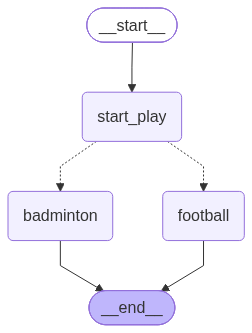

In [9]:
from IPython.display import Image, display
from langgraph.graph import StateGraph, START, END

# Build the graph
graph = StateGraph(State) # empty graph

# Add all the nodes
graph.add_node("start_play", start_play) # 1st param = node name, 2nd param = function name (here it's the same)
graph.add_node("football", football)
graph.add_node("badminton", badminton)

# Schedule the flow of the graph (connecting nodes)
graph.add_edge(START,"start_play")
graph.add_conditional_edges("start_play", random_play)
graph.add_edge("football", END)
graph.add_edge("badminton", END)

# Compile the graph
graph_builder = graph.compile()

# Vizualisation
display(Image(graph_builder.get_graph().draw_mermaid_png()))

#### Execution

In [11]:
graph_builder.invoke({"graph_info":"My name is Mathura, "})

Start Play node has been called.
Badminton node has been called.


{'graph_info': 'My name is Mathura, I am planning to play Badminton'}